Import libraries and load the cleaned dataset

In [16]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "Cleaned_Dataset.csv",
    encoding="latin1"
)

sns.set_theme(style="whitegrid")

print("Dataset Shape:", df.shape)
display(df.head())


Dataset Shape: (180519, 53)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


Scatter plot — Sales vs Order Profit

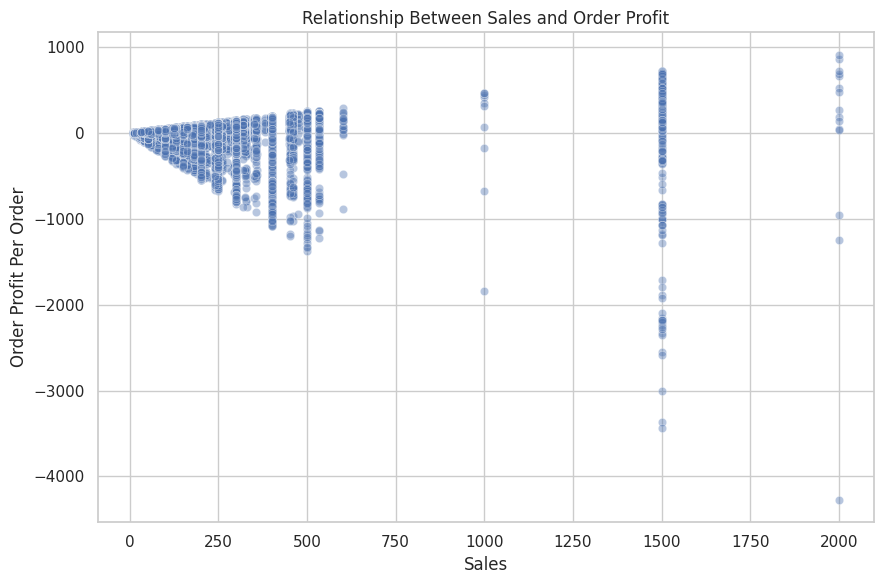

In [17]:

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Sales",
    y="Order Profit Per Order",
    alpha=0.4
)
plt.title("Relationship Between Sales and Order Profit")
plt.xlabel("Sales")
plt.ylabel("Order Profit Per Order")
plt.tight_layout()
plt.show()


Scatter Plot - Scheduled vs Actual Shipping Days

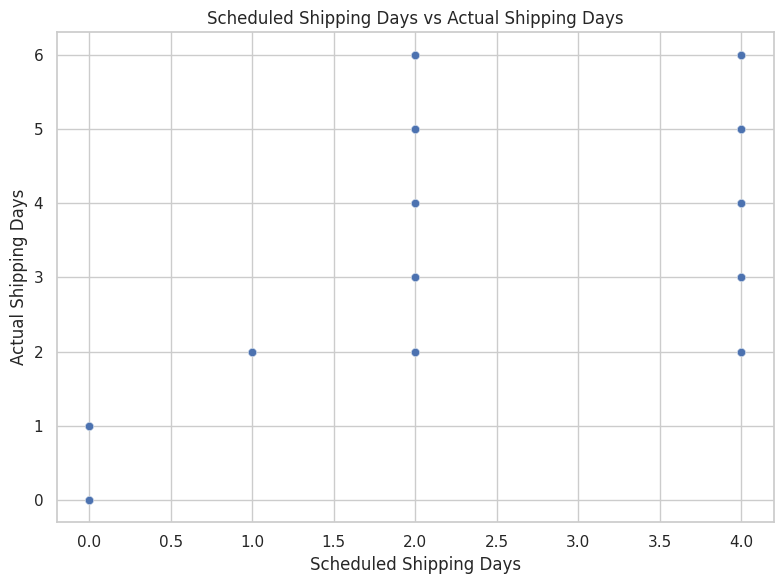

In [18]:

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="Days for shipment (scheduled)",
    y="Days for shipping (real)",
    alpha=0.4
)

plt.title("Scheduled Shipping Days vs Actual Shipping Days")
plt.xlabel("Scheduled Shipping Days")
plt.ylabel("Actual Shipping Days")

plt.tight_layout()
plt.show()


Boxplot — Shipping Mode vs Actual Shipping Duration

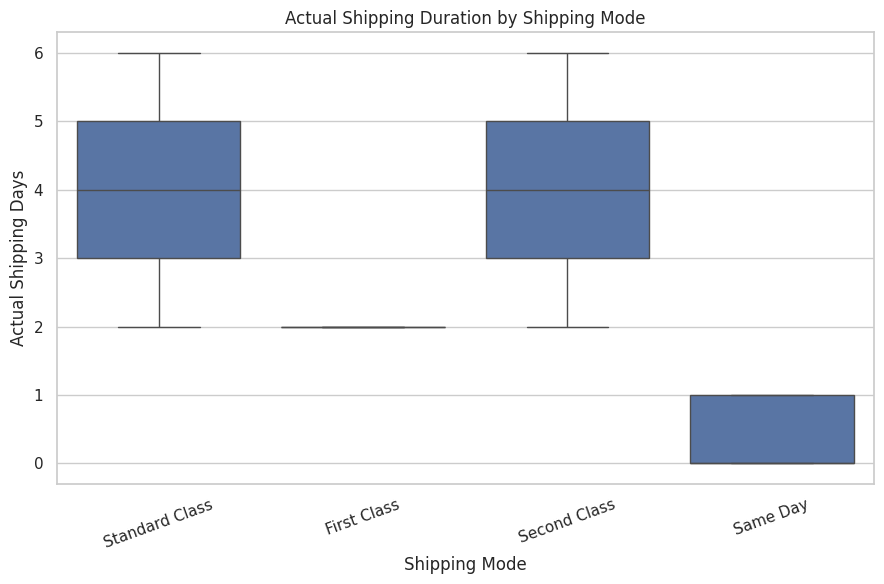

In [19]:

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="Shipping Mode",
    y="Days for shipping (real)"
)

plt.title("Actual Shipping Duration by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Actual Shipping Days")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()


Scatter plot — Discount vs Order Profit

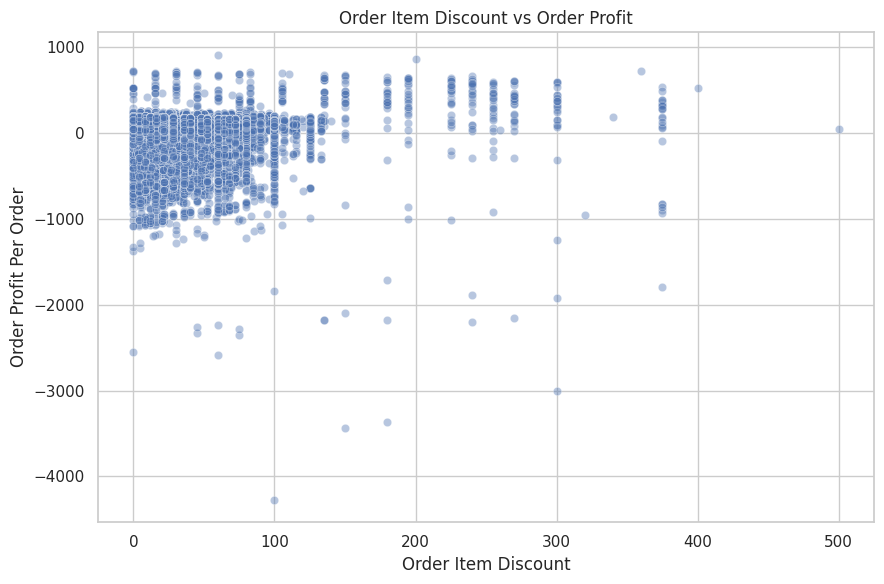

In [20]:

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Order Item Discount",
    y="Order Profit Per Order",
    alpha=0.4
)

plt.title("Order Item Discount vs Order Profit")
plt.xlabel("Order Item Discount")
plt.ylabel("Order Profit Per Order")

plt.tight_layout()
plt.show()


Grouped bar chart — Delivery Status by Shipping Mode

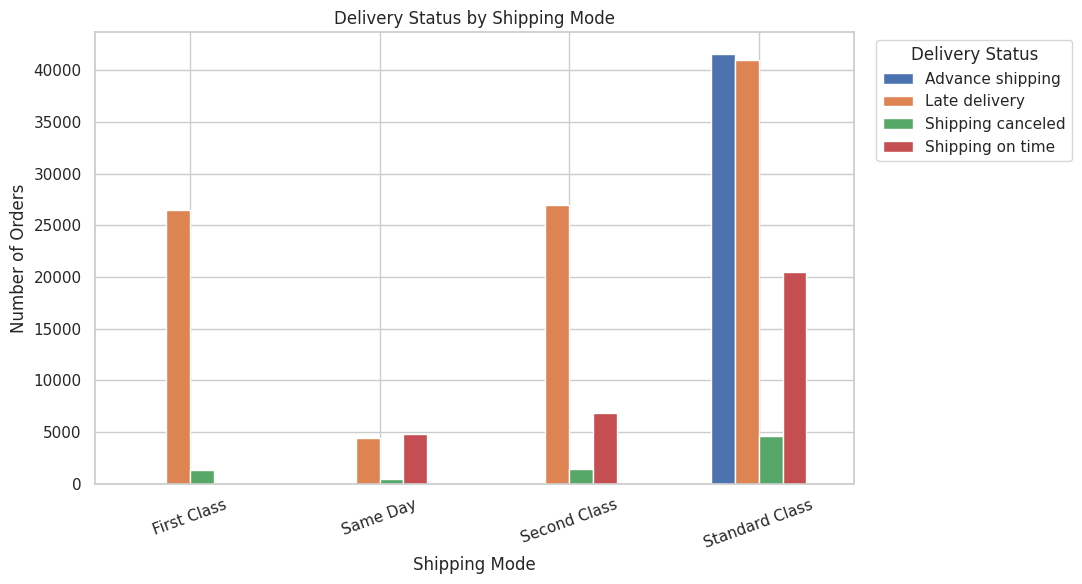

In [21]:

delivery_table = pd.crosstab(
    df["Shipping Mode"],
    df["Delivery Status"]
)

delivery_table.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Delivery Status by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Number of Orders")
plt.xticks(rotation=20)
plt.legend(title="Delivery Status", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


Correlation heatmap — Numerical relationships

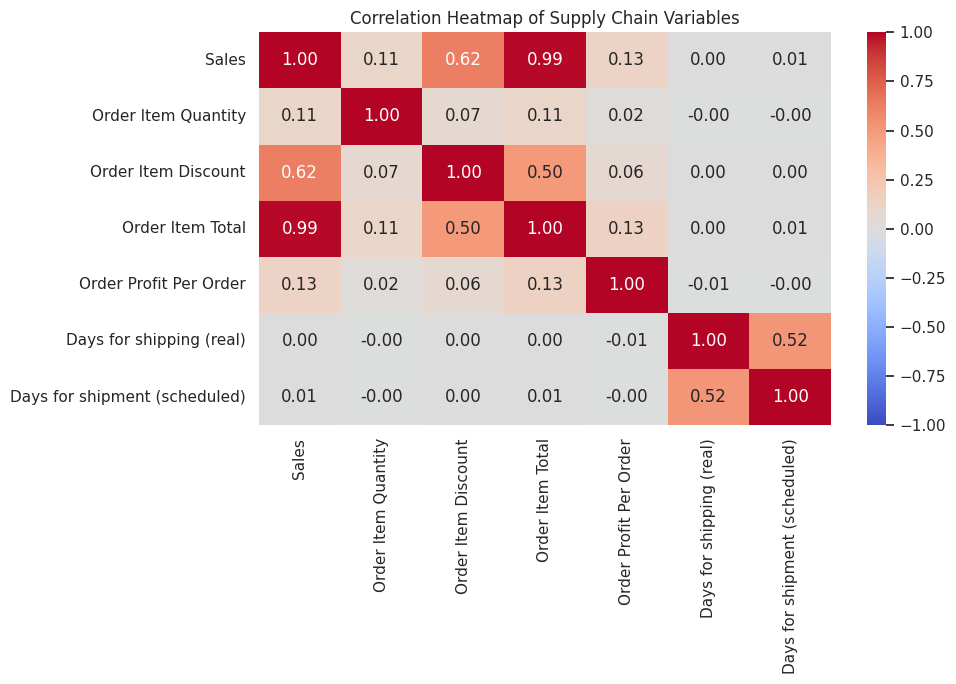

In [22]:

numeric_cols = [
    "Sales",
    "Order Item Quantity",
    "Order Item Discount",
    "Order Item Total",
    "Order Profit Per Order",
    "Days for shipping (real)",
    "Days for shipment (scheduled)"
]
numeric_cols = [
    col for col in numeric_cols if col in df.columns
]

plt.figure(figsize=(10, 7))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Supply Chain Variables")
plt.tight_layout()
plt.show()
